# Cybertron - EN3150 Assignment 03


In [1]:
import os
if not os.path.exists('requirements.txt'):
    !git clone -q https://github.com/Isira-Himal-Perera/CNN-for-Edge-Image-Classification.git repo
    %cd repo
!pip install -q -r requirements.txt
print('working directory:', os.getcwd())

/content/repo
working directory: /content/repo


In [2]:
from pathlib import Path
import torch
from IPython.display import Image, display

from src.data import get_data, make_loaders, SEED
from src.models import EdgeCNN, count_params, estimate_macs, load_pretrained, unfreeze_last_block
from src.experiment import seed_everything, optimizer_for, run_epochs, evaluate, describe_run

%matplotlib inline
import matplotlib.pyplot as plt

OUT = Path('results_notebook')
(OUT / 'models').mkdir(parents=True, exist_ok=True)
(OUT / 'plots').mkdir(parents=True, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch:', torch.__version__)

device: cuda | torch: 2.11.0+cu130


### Dataset

Splits digits 70/15/15 with seed 42 and previews sixteen training samples.

train: 1257 images (69.9%)
val  :  270 images (15.0%)
test :  270 images (15.0%)
classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


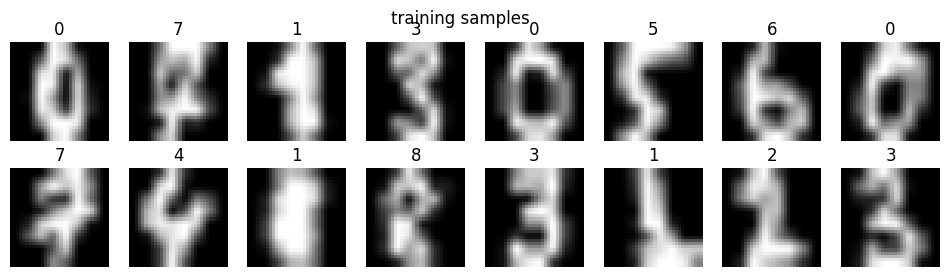

In [3]:
splits, classes, metadata = get_data('digits')
loaders = make_loaders(splits, batch_size=64)
image_size = splits['train'][0].shape[-1]

for name, (x, y) in splits.items():
    print(f'{name:5s}: {len(y):4d} images ({100 * len(y) / 1797:.1f}%)')
print('classes:', classes)

x, y = splits['train']
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for ax, img, label in zip(axes.flat, x[:16], y[:16]):
    ax.imshow(img[0], cmap='gray')
    ax.set_title(str(int(label)))
    ax.axis('off')
fig.suptitle('training samples')
plt.show()

### Models

Builds both CNNs and prints parameter counts and per-image MACs.

In [4]:
model_a = EdgeCNN(len(classes), lightweight=False)
model_b = EdgeCNN(len(classes), lightweight=True)

for name, m in [('Model A (standard)', model_a), ('Model B (separable)', model_b)]:
    params = count_params(m)
    print(f'{name:22s} params={params:>7,d}  MACs/image={estimate_macs(m, image_size):,}')

assert count_params(model_b) <= 100_000, 'Model B exceeds the 100k parameter limit'
print('Model B is within the 100k parameter limit')

Model A (standard)     params= 26,218  MACs/image=2,804,032
Model B (separable)    params=  5,813  MACs/image=396,608
Model B is within the 100k parameter limit


### Training helpers

Defines the train and evaluate helpers that every run below calls.

In [5]:
def train(model, epochs, optim_name, lr=None, history=None):
    seed_everything()
    opt = optimizer_for(optim_name, model, lr)
    return run_epochs(model, loaders, epochs, opt, device, history)


def evaluate_and_plot(stem, model, history):
    metrics = evaluate(model, loaders['test'], len(classes), device)
    rec = describe_run(model, history, metrics, OUT, stem, classes, image_size, device)
    display(Image(filename=str(OUT / 'plots' / f'{stem}_loss.png')))
    display(Image(filename=str(OUT / 'plots' / f'{stem}_confusion.png')))
    print(f"{stem}: test accuracy {100 * metrics['accuracy']:.1f}%  "
          f"macro precision {100 * metrics['precision_macro']:.1f}%  "
          f"macro recall {100 * metrics['recall_macro']:.1f}%\n")
    return rec


results = {}

### Model A with Adam

Trains Model A for 25 epochs and writes its loss curve, confusion matrix and test metrics.

RUNNING: model_a_adam
epoch 01 train-loss=2.1785 val-loss=2.2975 val-accuracy=0.104 time=3.8s
epoch 02 train-loss=1.9239 val-loss=2.1514 val-accuracy=0.159 time=0.1s
epoch 03 train-loss=1.6154 val-loss=1.7148 val-accuracy=0.519 time=0.1s
epoch 04 train-loss=1.2618 val-loss=1.2571 val-accuracy=0.859 time=0.2s
epoch 05 train-loss=0.9451 val-loss=0.9347 val-accuracy=0.848 time=0.3s
epoch 06 train-loss=0.6799 val-loss=0.7118 val-accuracy=0.863 time=0.2s
epoch 07 train-loss=0.4904 val-loss=0.4878 val-accuracy=0.937 time=0.2s
epoch 08 train-loss=0.3714 val-loss=0.7994 val-accuracy=0.726 time=0.2s
epoch 09 train-loss=0.2819 val-loss=0.4334 val-accuracy=0.896 time=0.2s
epoch 10 train-loss=0.2187 val-loss=0.2908 val-accuracy=0.952 time=0.2s
epoch 11 train-loss=0.1734 val-loss=0.2034 val-accuracy=0.981 time=0.1s
epoch 12 train-loss=0.1318 val-loss=0.2131 val-accuracy=0.978 time=0.2s
epoch 13 train-loss=0.1064 val-loss=0.3674 val-accuracy=0.885 time=0.1s
epoch 14 train-loss=0.0941 val-loss=0.2108

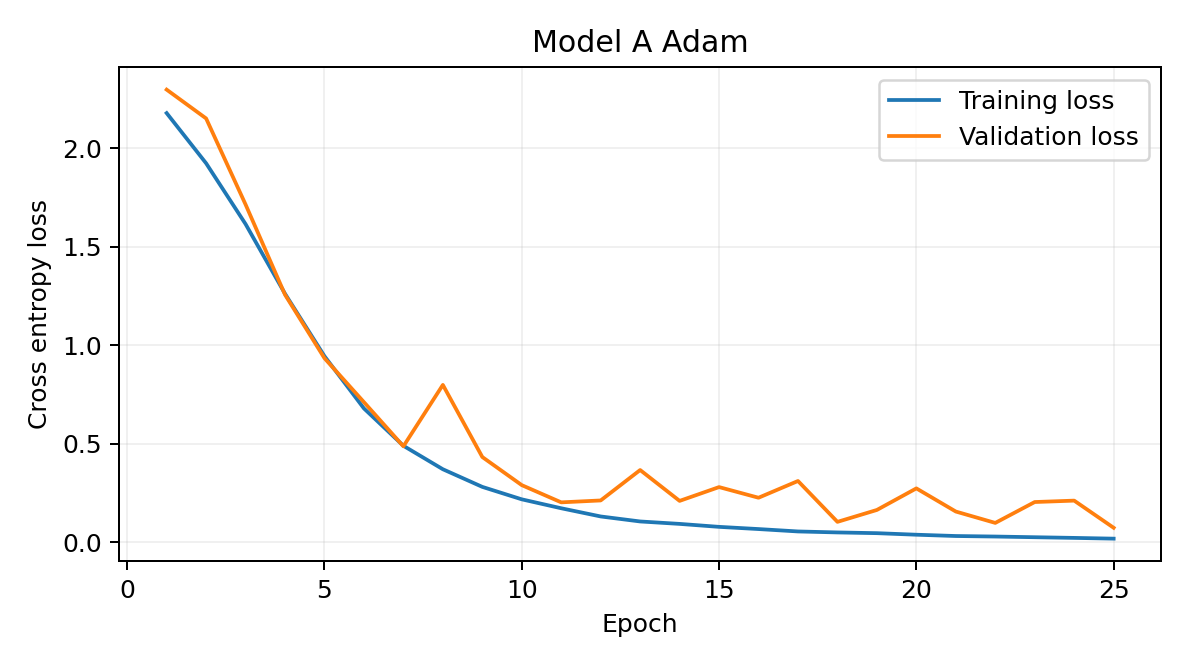

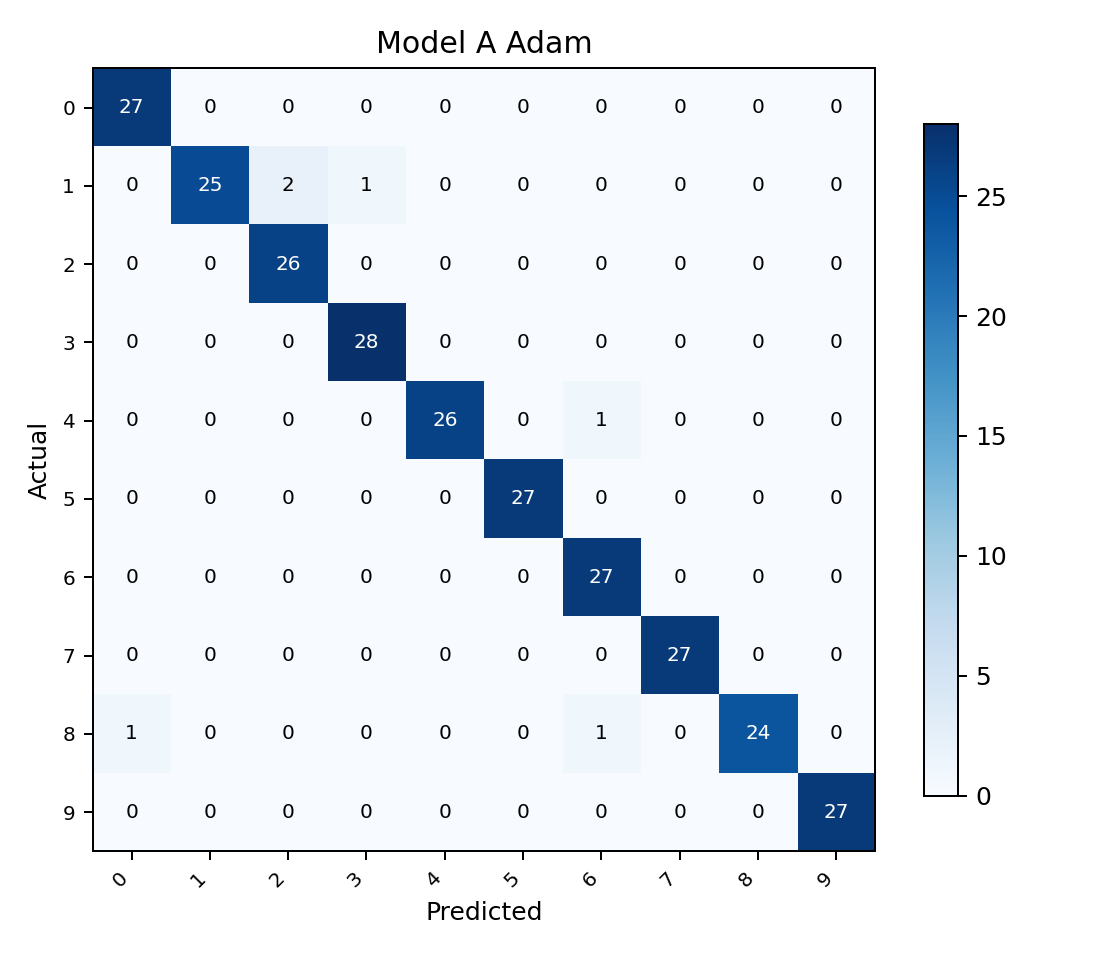

model_a_adam: test accuracy 97.8%  macro precision 97.9%  macro recall 97.8%



In [6]:
print('RUNNING: model_a_adam')
m = EdgeCNN(len(classes), lightweight=False)
hist = train(m, 25, 'adam')
results['model_a_adam'] = evaluate_and_plot('model_a_adam', m, hist)

### Model B with Adam

Trains the separable Model B with Adam and records the same plots and metrics.

RUNNING: model_b_adam
epoch 01 train-loss=2.2787 val-loss=2.3059 val-accuracy=0.100 time=0.1s
epoch 02 train-loss=2.1986 val-loss=2.2850 val-accuracy=0.170 time=0.1s
epoch 03 train-loss=2.0966 val-loss=2.1489 val-accuracy=0.281 time=0.1s
epoch 04 train-loss=1.9553 val-loss=1.9341 val-accuracy=0.381 time=0.1s
epoch 05 train-loss=1.7763 val-loss=1.7179 val-accuracy=0.619 time=0.1s
epoch 06 train-loss=1.5733 val-loss=1.5308 val-accuracy=0.615 time=0.1s
epoch 07 train-loss=1.3546 val-loss=1.3727 val-accuracy=0.574 time=0.1s
epoch 08 train-loss=1.1627 val-loss=1.4515 val-accuracy=0.404 time=0.1s
epoch 09 train-loss=1.0050 val-loss=1.0344 val-accuracy=0.704 time=0.1s
epoch 10 train-loss=0.8570 val-loss=0.8899 val-accuracy=0.781 time=0.1s
epoch 11 train-loss=0.7485 val-loss=0.9936 val-accuracy=0.711 time=0.1s
epoch 12 train-loss=0.6585 val-loss=0.6721 val-accuracy=0.848 time=0.1s
epoch 13 train-loss=0.5802 val-loss=0.7816 val-accuracy=0.789 time=0.1s
epoch 14 train-loss=0.5192 val-loss=0.6421

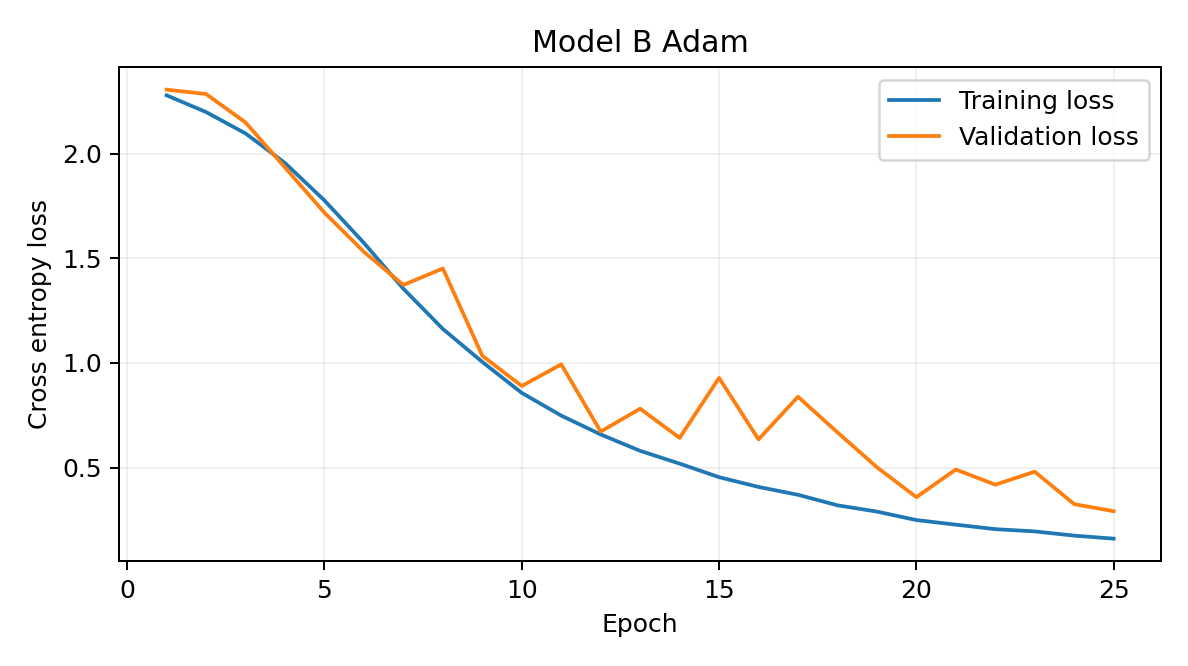

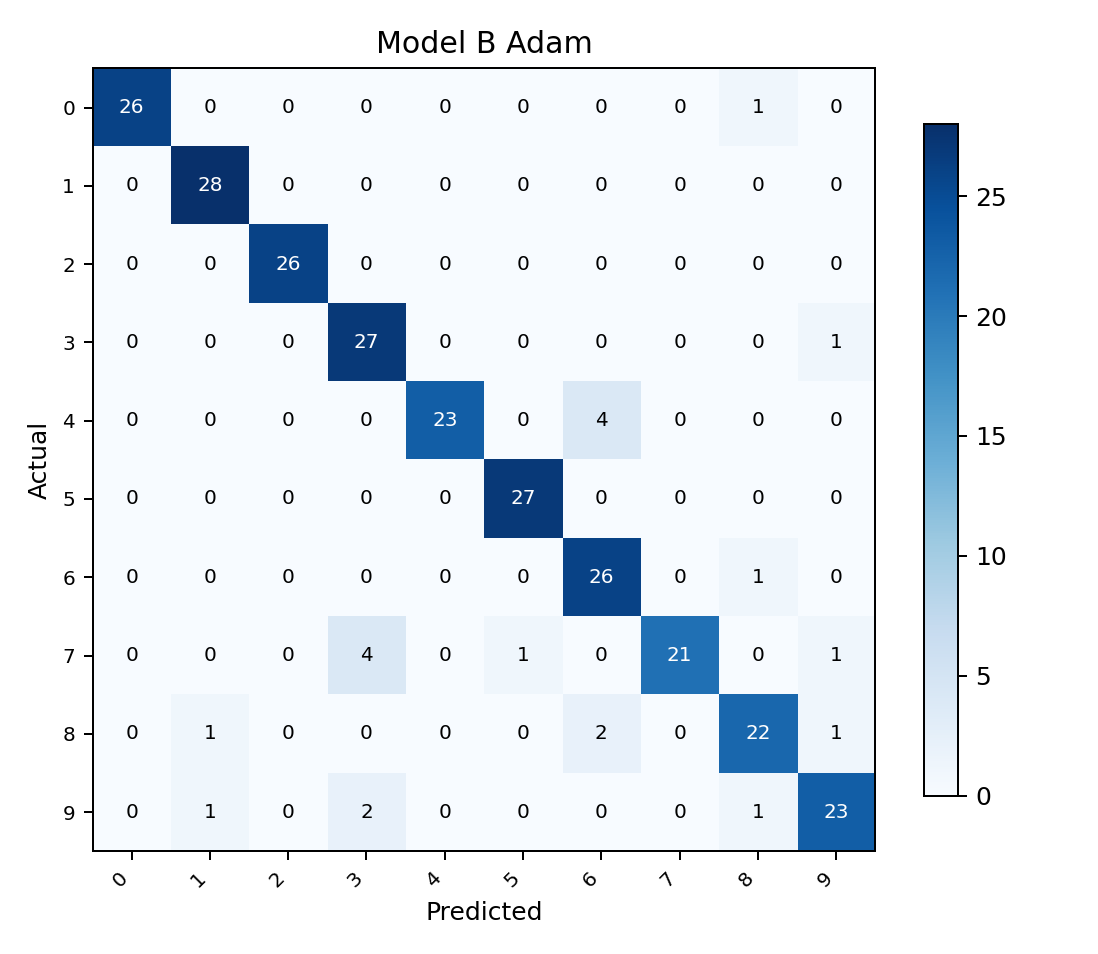

model_b_adam: test accuracy 92.2%  macro precision 92.9%  macro recall 92.2%



In [7]:
print('RUNNING: model_b_adam')
m = EdgeCNN(len(classes), lightweight=True)
hist = train(m, 25, 'adam')
results['model_b_adam'] = evaluate_and_plot('model_b_adam', m, hist)

### Model B with SGD

Runs Model B with plain SGD to show it barely learns on this budget.

RUNNING: model_b_sgd
epoch 01 train-loss=2.3056 val-loss=2.3061 val-accuracy=0.100 time=0.1s
epoch 02 train-loss=2.2877 val-loss=2.3018 val-accuracy=0.130 time=0.1s
epoch 03 train-loss=2.2744 val-loss=2.2834 val-accuracy=0.152 time=0.1s
epoch 04 train-loss=2.2638 val-loss=2.2614 val-accuracy=0.230 time=0.1s
epoch 05 train-loss=2.2517 val-loss=2.2477 val-accuracy=0.289 time=0.1s
epoch 06 train-loss=2.2396 val-loss=2.2353 val-accuracy=0.222 time=0.1s
epoch 07 train-loss=2.2248 val-loss=2.2216 val-accuracy=0.319 time=0.1s
epoch 08 train-loss=2.2083 val-loss=2.2070 val-accuracy=0.374 time=0.1s
epoch 09 train-loss=2.1890 val-loss=2.1909 val-accuracy=0.330 time=0.1s
epoch 10 train-loss=2.1659 val-loss=2.1664 val-accuracy=0.311 time=0.1s
epoch 11 train-loss=2.1396 val-loss=2.1462 val-accuracy=0.304 time=0.1s
epoch 12 train-loss=2.1113 val-loss=2.1166 val-accuracy=0.393 time=0.1s
epoch 13 train-loss=2.0755 val-loss=2.0828 val-accuracy=0.430 time=0.1s
epoch 14 train-loss=2.0390 val-loss=2.0568 

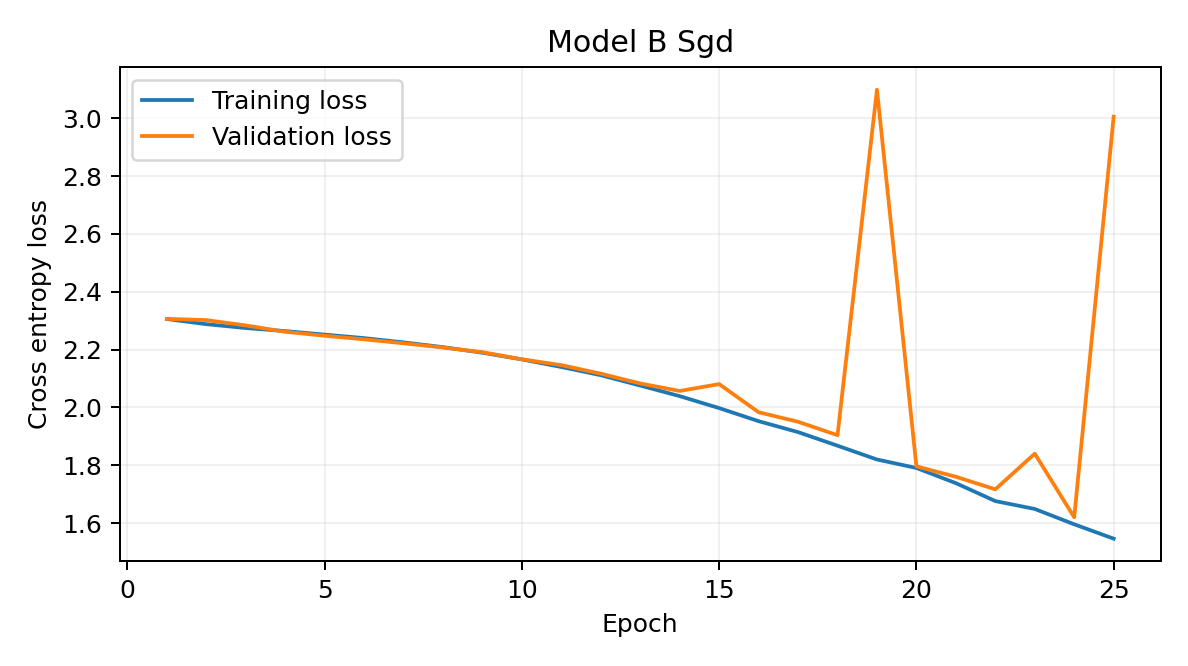

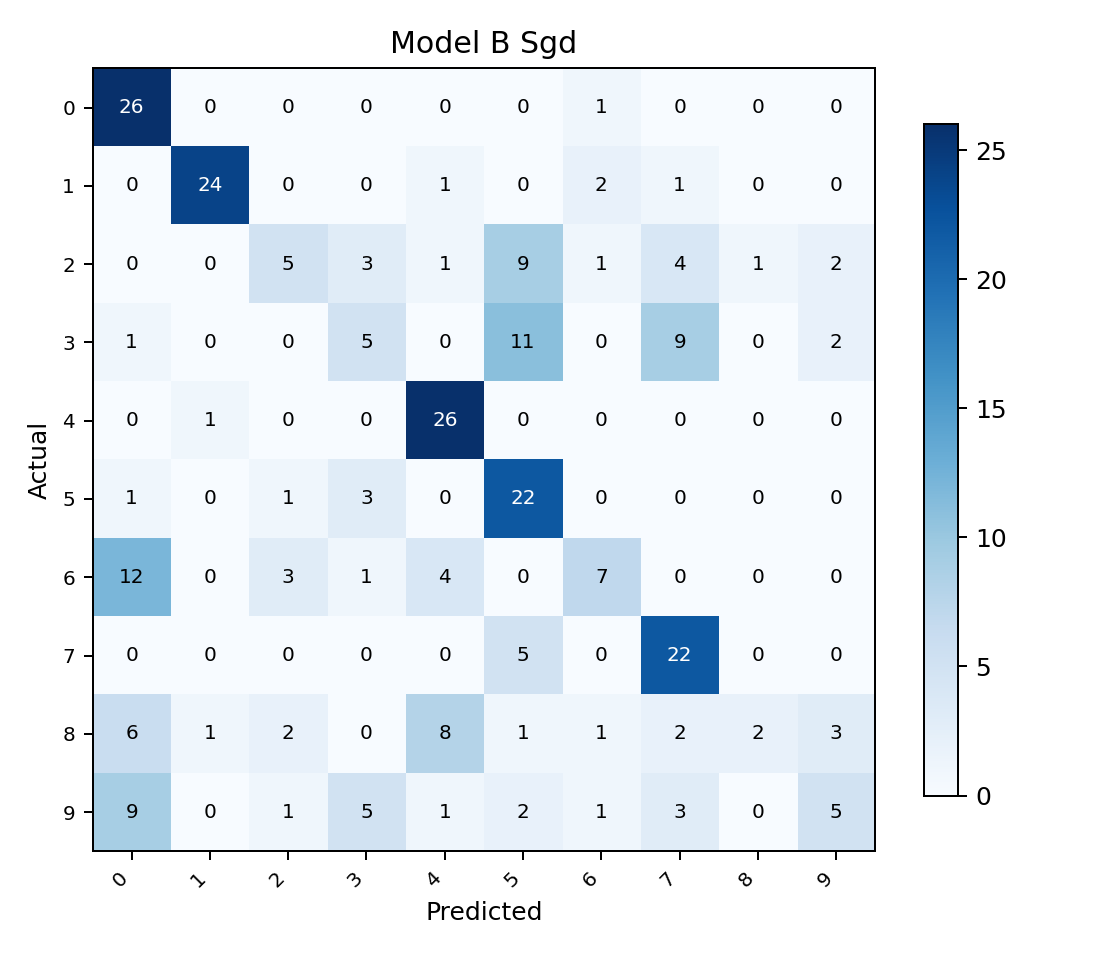

model_b_sgd: test accuracy 53.3%  macro precision 53.4%  macro recall 53.0%



In [8]:
print('RUNNING: model_b_sgd')
m = EdgeCNN(len(classes), lightweight=True)
hist = train(m, 25, 'sgd')
results['model_b_sgd'] = evaluate_and_plot('model_b_sgd', m, hist)

### Model B with momentum

Runs Model B with SGD momentum to show training recovers over plain SGD.

RUNNING: model_b_momentum
epoch 01 train-loss=2.2938 val-loss=2.3048 val-accuracy=0.100 time=0.1s
epoch 02 train-loss=2.2058 val-loss=2.2914 val-accuracy=0.111 time=0.1s
epoch 03 train-loss=2.0329 val-loss=2.2213 val-accuracy=0.104 time=0.1s
epoch 04 train-loss=1.7461 val-loss=2.9355 val-accuracy=0.119 time=0.1s
epoch 05 train-loss=1.3949 val-loss=3.7846 val-accuracy=0.115 time=0.1s
epoch 06 train-loss=1.1259 val-loss=1.8207 val-accuracy=0.344 time=0.1s
epoch 07 train-loss=0.8875 val-loss=1.3171 val-accuracy=0.537 time=0.1s
epoch 08 train-loss=0.8172 val-loss=0.8184 val-accuracy=0.693 time=0.1s
epoch 09 train-loss=0.6735 val-loss=1.5486 val-accuracy=0.437 time=0.1s
epoch 10 train-loss=0.5226 val-loss=1.2845 val-accuracy=0.574 time=0.1s
epoch 11 train-loss=0.4278 val-loss=1.9208 val-accuracy=0.459 time=0.1s
epoch 12 train-loss=0.3748 val-loss=1.7785 val-accuracy=0.411 time=0.1s
epoch 13 train-loss=0.3589 val-loss=0.9664 val-accuracy=0.667 time=0.1s
epoch 14 train-loss=0.2870 val-loss=2.

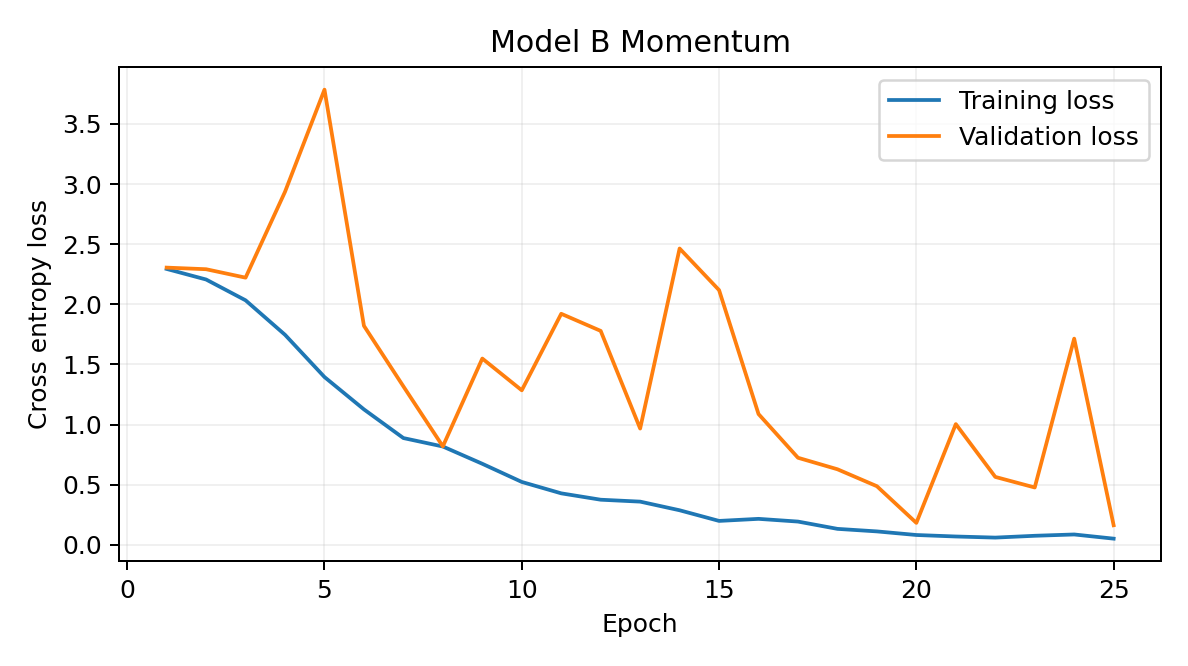

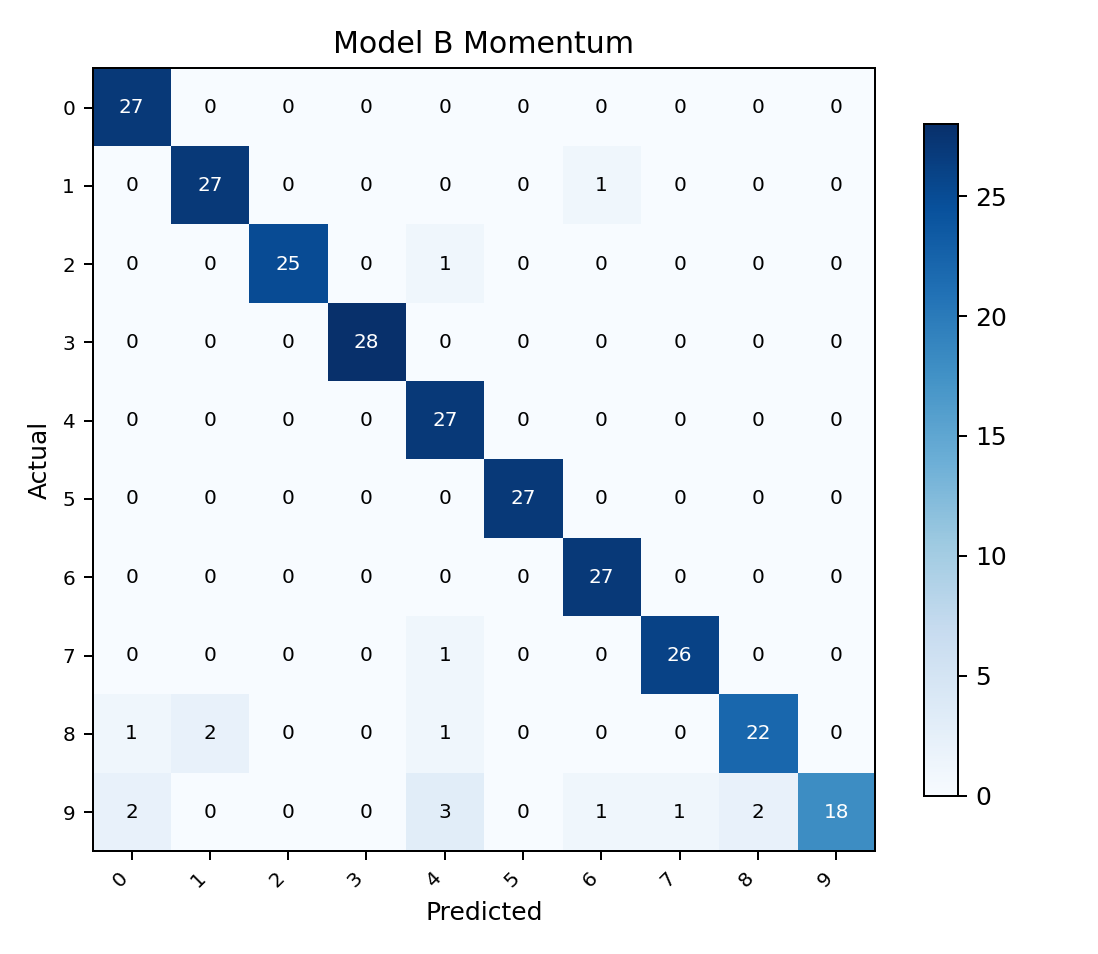

model_b_momentum: test accuracy 94.1%  macro precision 94.6%  macro recall 94.0%



In [9]:
print('RUNNING: model_b_momentum')
m = EdgeCNN(len(classes), lightweight=True)
hist = train(m, 25, 'momentum')
results['model_b_momentum'] = evaluate_and_plot('model_b_momentum', m, hist)

### MobileNetV2 fine-tuning

Fine-tunes pretrained MobileNetV2 in two phases as the larger comparison baseline.

FINE-TUNING: mobilenet_v2
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 102MB/s] 


epoch 01 train-loss=2.2443 val-loss=2.1986 val-accuracy=0.326 time=0.4s
epoch 02 train-loss=2.1418 val-loss=2.1145 val-accuracy=0.419 time=0.2s
epoch 03 train-loss=2.0580 val-loss=2.0429 val-accuracy=0.448 time=0.2s
epoch 04 train-loss=1.9852 val-loss=1.9813 val-accuracy=0.496 time=0.2s
epoch 05 train-loss=1.9207 val-loss=1.9256 val-accuracy=0.544 time=0.2s
epoch 06 train-loss=1.8661 val-loss=1.8758 val-accuracy=0.563 time=0.2s
epoch 07 train-loss=1.8130 val-loss=1.8302 val-accuracy=0.578 time=0.2s
epoch 08 train-loss=1.1942 val-loss=0.9688 val-accuracy=0.711 time=0.3s
epoch 09 train-loss=0.8878 val-loss=0.7776 val-accuracy=0.756 time=0.2s
epoch 10 train-loss=0.7068 val-loss=0.6741 val-accuracy=0.793 time=0.2s


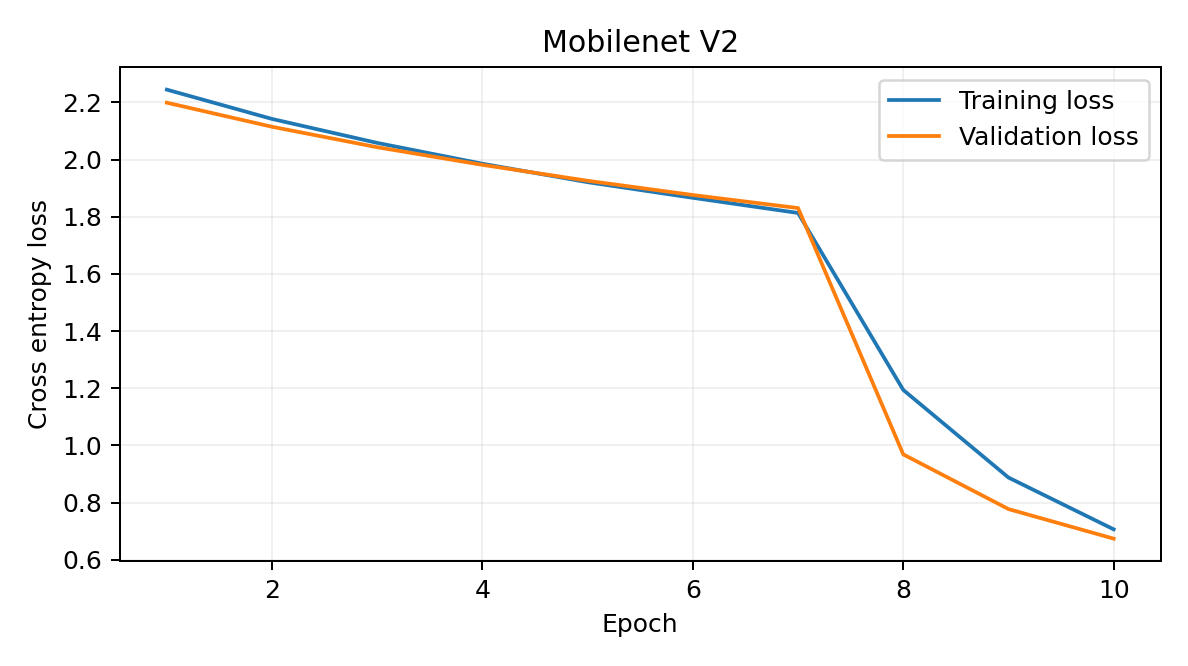

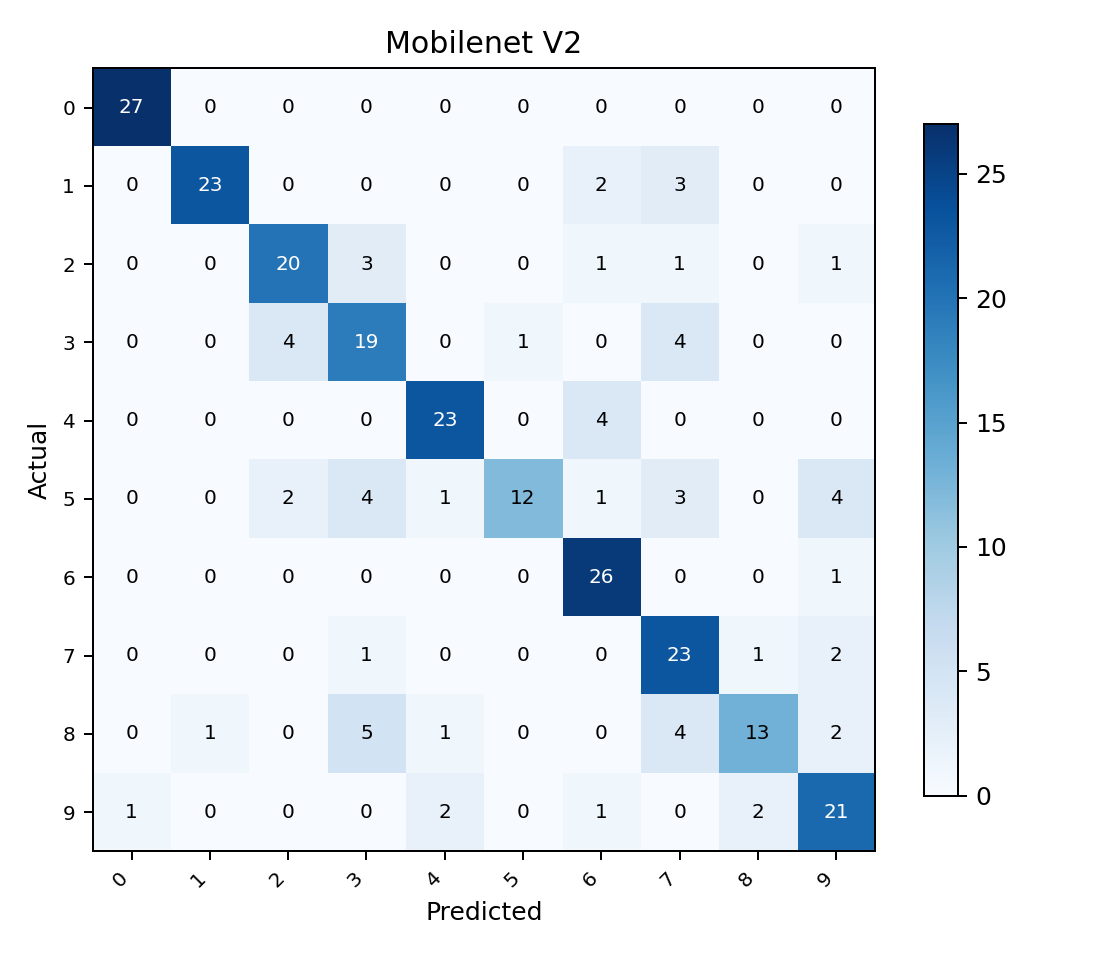

mobilenet_v2: test accuracy 76.7%  macro precision 79.0%  macro recall 76.6%



In [10]:
print('FINE-TUNING: mobilenet_v2')
seed_everything()
m = load_pretrained('mobilenet_v2', len(classes))
hist = train(m, 7, 'adam', 0.001)
unfreeze_last_block(m, 'mobilenet_v2')
hist = train(m, 3, 'adam', 0.0001, hist)
results['mobilenet_v2'] = evaluate_and_plot('mobilenet_v2', m, hist)

### SqueezeNet1.1 fine-tuning

Fine-tunes SqueezeNet1.1 the same way to complete the comparison.

FINE-TUNING: squeezenet1_1
Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100%|██████████| 4.73M/4.73M [00:00<00:00, 63.2MB/s]


epoch 01 train-loss=5.7162 val-loss=2.2333 val-accuracy=0.137 time=0.2s
epoch 02 train-loss=2.2940 val-loss=2.2361 val-accuracy=0.133 time=0.1s
epoch 03 train-loss=2.1914 val-loss=2.2049 val-accuracy=0.163 time=0.1s
epoch 04 train-loss=2.1564 val-loss=2.1603 val-accuracy=0.178 time=0.1s
epoch 05 train-loss=2.1784 val-loss=2.1572 val-accuracy=0.181 time=0.1s
epoch 06 train-loss=2.1475 val-loss=2.1386 val-accuracy=0.189 time=0.1s
epoch 07 train-loss=2.1350 val-loss=2.1110 val-accuracy=0.200 time=0.1s
epoch 08 train-loss=2.1136 val-loss=2.1057 val-accuracy=0.204 time=0.1s
epoch 09 train-loss=2.0922 val-loss=2.1026 val-accuracy=0.219 time=0.1s
epoch 10 train-loss=2.0587 val-loss=2.0382 val-accuracy=0.270 time=0.1s


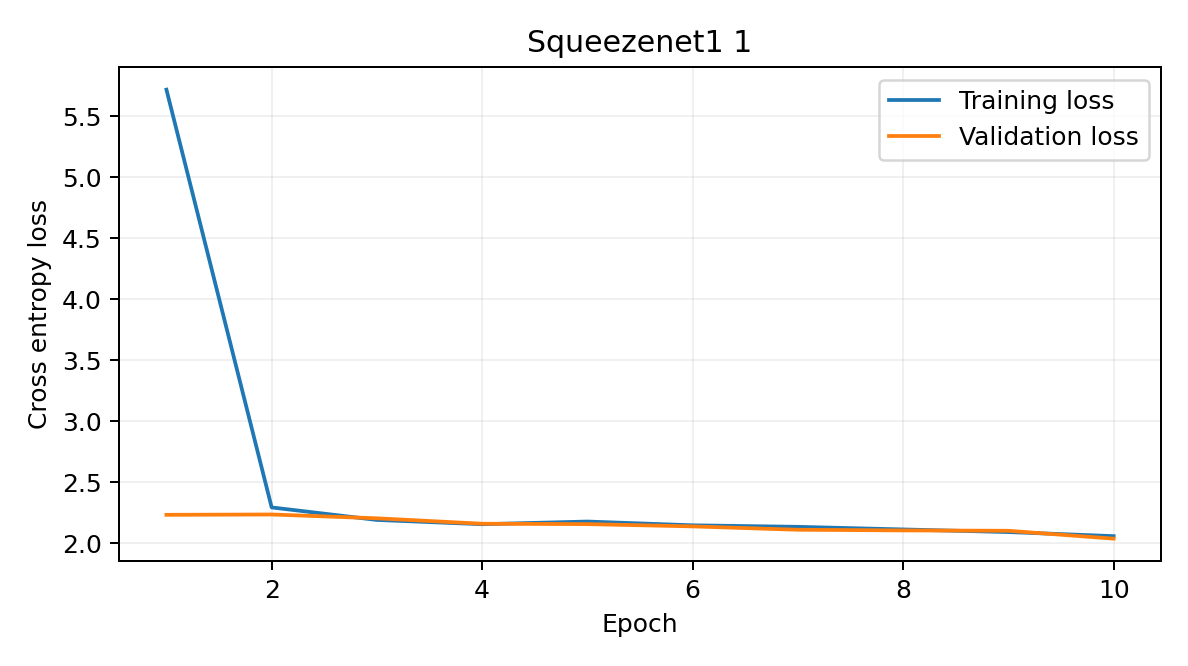

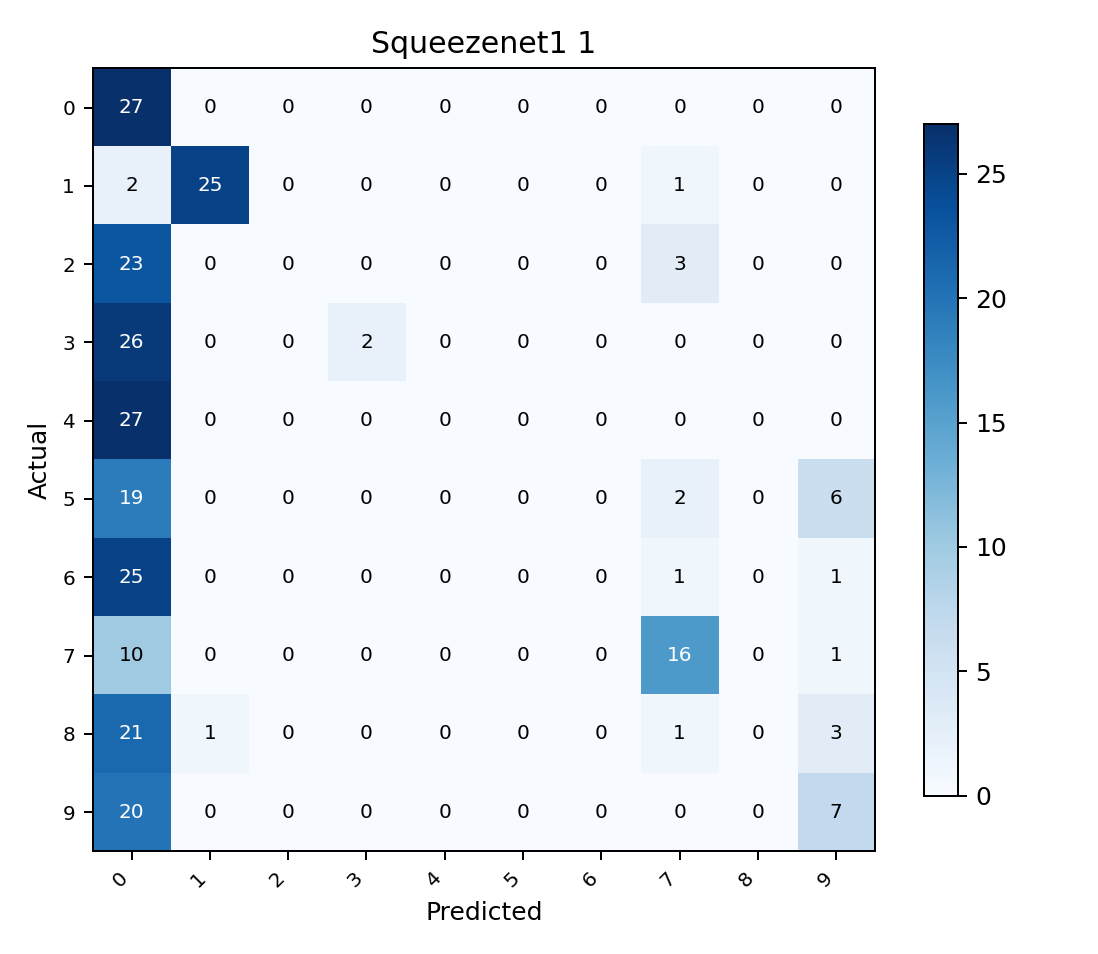

squeezenet1_1: test accuracy 28.5%  macro precision 31.5%  macro recall 28.2%



In [11]:
print('FINE-TUNING: squeezenet1_1')
seed_everything()
m = load_pretrained('squeezenet1_1', len(classes))
hist = train(m, 7, 'adam', 0.001)
unfreeze_last_block(m, 'squeezenet1_1')
hist = train(m, 3, 'adam', 0.0001, hist)
results['squeezenet1_1'] = evaluate_and_plot('squeezenet1_1', m, hist)

### Final comparison table

Prints parameters, size, MACs and test accuracy for all six models side by side.

In [12]:
print(f"{'model':<18}{'params':>12}{'size (KB)':>12}{'MACs/image':>14}{'test accuracy':>15}")
for stem, r in results.items():
    print(f"{stem:<18}{r['params_total']:>12,d}{r['size_kb']:>12.1f}"
          f"{r['estimated_macs']:>14,d}{100 * r['metrics']['accuracy']:>14.1f}%")

model                   params   size (KB)    MACs/image  test accuracy
model_a_adam            26,218       111.7     2,804,032          97.8%
model_b_adam             5,813        33.2       396,608          92.2%
model_b_sgd              5,813        33.1       396,608          53.3%
model_b_momentum         5,813        33.3       396,608          94.1%
mobilenet_v2         2,236,682      8973.2     6,124,928          76.7%
squeezenet1_1          727,626      2861.6     2,995,904          28.5%
